# Supplementary Figure S3: mutual information of syllable transitions

Reads `mutual_information_data.pkl`, made by Cell M1 of `data_figs`.

* **A, C**: each bird's mean bootstrap MI in each condition (small points, one line per bird) and the mean ± SEM across birds (large points).
* **B, D**: |ΔMI| = |MI(regular air) − MI(heliox)| per bird. Outlined points: P < 0.05 against the within-condition null. Black point: mean ± 1.96 SEM across birds.



In [1]:
# Setup: paths, figure style, data
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'mutual_information_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16,
                     'xtick.labelsize': 15, 'ytick.labelsize': 14, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False})

mi = pd.read_pickle(DATA_PATH)
birds = mi['birds']            # one row per bird: bootstrap means, dMI, P
draws = mi['bootstrap']        # every bootstrap draw, used only by the check cell
print(birds.round(3).to_string(index=False))

    species        bird  mi_regair  mi_heliox    dmi  dmi_lo  dmi_hi     p  n_boot  n_null
   starling s_b1349h_23      2.470      2.280  0.190   0.092   0.289 0.019    1000    1000
   starling  s_b1354_25      2.155      2.055  0.100  -0.052   0.253 0.048    1000    1000
   starling s_b1364h_25      2.398      2.221  0.177   0.083   0.280 0.001    1000    1000
   starling s_b1481h_24      3.423      3.311  0.112  -0.149   0.393 0.337    1000    1000
   starling s_b1484h_24      2.504      2.591 -0.086  -0.209   0.024 0.199    1000    1000
   starling s_b1556h_24      2.793      3.155 -0.363  -0.578  -0.151 0.001    1000    1000
zebra_finch  z_c8c19_24      1.798      1.763  0.034   0.003   0.065 0.034    1000    1000
zebra_finch z_g14g16_24      1.585      1.585  0.000  -0.000   0.000 0.313    1000    1000
zebra_finch  z_p4g13_23      0.981      0.978  0.003  -0.015   0.019 0.766    1000    1000
zebra_finch   z_p7y2_23      1.132      1.054  0.078  -0.039   0.192 0.113    1000    1000

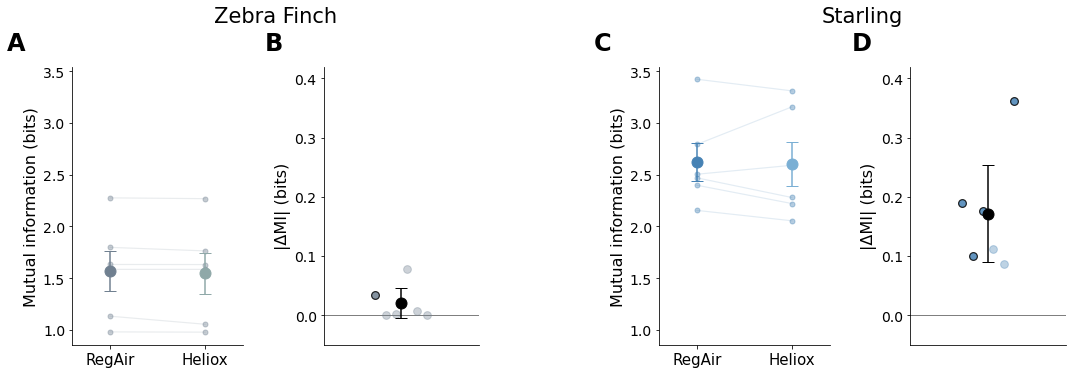

In [2]:
# Supplementary Figure S3
SPECIES = {  # colours of the published figure
    'zebra_finch': dict(title='Zebra Finch', regair='#708090', heliox='#8FA8A8', points='slategray'),
    'starling':    dict(title='Starling',    regair='#4682B4', heliox='#7AAFD4', points='steelblue'),
}

fig = plt.figure(figsize=(15, 5.6))
# A B (gap) C D; the empty column keeps the two species apart
grid = fig.add_gridspec(1, 5, width_ratios=[1.1, 1, 0.12, 1.1, 1], left=0.07, right=0.99,
                        bottom=0.11, top=0.8, wspace=0.6)
ax_mi = {'zebra_finch': fig.add_subplot(grid[0])}
ax_mi['starling'] = fig.add_subplot(grid[3], sharey=ax_mi['zebra_finch'])   # same MI scale for both species
ax_dmi = {'zebra_finch': fig.add_subplot(grid[1]), 'starling': fig.add_subplot(grid[4])}

for species, style in SPECIES.items():
    d = birds[birds['species'] == species].sort_values('bird')
    r, h = d['mi_regair'].to_numpy(), d['mi_heliox'].to_numpy()

    # ---- A, C: MI per condition --------------------------------------------------------------
    ax = ax_mi[species]
    for ri, hi in zip(r, h):
        ax.plot([0, 1], [ri, hi], color=style['regair'], alpha=0.15, lw=1.2, zorder=1)
    ax.scatter(np.zeros(len(r)), r, s=25, alpha=0.4, color=style['regair'], zorder=2)
    ax.scatter(np.ones(len(h)), h, s=25, alpha=0.4, color=style['regair'], zorder=2)
    for x, v, colour in [(0, r, style['regair']), (1, h, style['heliox'])]:
        ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=11, capsize=6,
                    color=colour, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['RegAir', 'Heliox'])
    ax.set_xlim(-0.4, 1.4)
    ax.set_ylabel('Mutual information (bits)')
    ax.tick_params(axis='y', labelleft=True)

    # ---- B, D: size of the condition effect per bird ------------------------------------------
    # |dMI| rather than dMI: the direction of the effect differs between birds
    ax = ax_dmi[species]
    a = d['dmi'].abs().to_numpy()
    sig = d['p'].to_numpy() < 0.05
    x = np.linspace(-0.15, 0.15, len(a))
    ax.axhline(0, lw=1, color='k', alpha=0.5)
    ax.scatter(x[sig], a[sig], s=60, color=style['points'], alpha=0.85, edgecolor='k', linewidths=1.2, zorder=2)
    ax.scatter(x[~sig], a[~sig], s=60, color=style['points'], alpha=0.35, zorder=2)
    ax.errorbar(0, a.mean(), yerr=1.96 * a.std(ddof=1) / np.sqrt(len(a)), fmt='o', ms=11, capsize=6,
                color='black', zorder=5)
    ax.set_xticks([])
    ax.set_xlim(-0.45, 0.45)
    ax.set_ylim(-0.05, 0.42)
    ax.set_ylabel('|ΔMI| (bits)')

    # species name centred over its two panels
    left, right = ax_mi[species].get_position(), ax.get_position()
    fig.text((left.x0 + right.x1) / 2, 0.9, style['title'], ha='center', va='bottom', fontsize=21)

for letter, ax in zip('ABCD', [ax_mi['zebra_finch'], ax_dmi['zebra_finch'], ax_mi['starling'], ax_dmi['starling']]):
    ax.text(-0.38, 1.04, letter, transform=ax.transAxes, fontsize=24, fontweight='bold', va='bottom')

fig.savefig(os.path.join(FIG_DIR, 'supp_fig_S3_mutual_information.png'), bbox_inches='tight')
fig.savefig(os.path.join(FIG_DIR, 'supp_fig_S3_mutual_information.pdf'), bbox_inches='tight')
plt.show()